# Final evaluation, lessons and capstone story

**Early Prediction of Long-Running Administrative Cases: A Proof of Concept for SPAR**

This notebook **summarises and interprets** the completed experiment. It does not run a new experiment.

> **The Day-14 experiment in `04_modeling.ipynb` is the final, primary result.** The 2014 test period has already been scored, so
> nothing here changes the features, snapshot, target, model parameters or probability threshold. The locked experiment is
> re-run once **only to reproduce** its recorded numbers, and the notebook stops if any of them differ.

**Research question:** *Can information available 14 days after an administrative case starts predict whether it will become a long-running case?*

**Answer:** *Not reliably in this dataset. A weak signal appeared on the 2013 validation period, but on the later 2014 test period the
models ranked cases no better than chance.*

# 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pm4py

candidates = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (folder for folder in candidates
     if (folder / "notebooks" / "01_data_loading.ipynb").is_file()
     and (folder / "src").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Start Jupyter from inside the capstone project.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src import features as F
from src import models as M

features_path = project_root / "data" / "processed" / "case_features_14d.csv"
xes_path = project_root / "data" / "raw" / "BPIC15_1.xes"
figures_dir = project_root / "outputs" / "figures"
for path in (features_path, xes_path):
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path.relative_to(project_root)} — run notebooks 01–04 first.")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 100)



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




# 2. Reproduce the locked experiment

The frozen configuration (`src/models.py`: `LOCKED_*` constants and `reproduce_locked_experiment`) is re-run exactly as in
notebook 04. The values recorded there are listed below, and the notebook **fails** if anything differs.

In [2]:
df = pm4py.convert_to_dataframe(pm4py.read_xes(str(xes_path), return_legacy_log_object=True))
df[F.EVENT_ORDER] = np.arange(len(df))
timing = F.case_timing(df)
snap = F.snapshot_events(F.prepare_events(df), timing)
table = F.load_features_csv(features_path).set_index("case_id")

locked = M.reproduce_locked_experiment(table, snap)
split, labels = locked["split"], locked["labels"]
THRESHOLD = M.LOCKED_PROBABILITY_THRESHOLD
FINAL = M.LOCKED_FINAL_MODEL

# Values recorded in 04_modeling.ipynb (rounded to 3 decimals)
RECORDED = {
    ("logistic (balanced)", "validation"): dict(precision=0.300, recall=1.000, f1=0.462, roc_auc=0.609, pr_auc=0.377),
    ("logistic (balanced)", "test"): dict(precision=0.144, recall=1.000, f1=0.252, roc_auc=0.528, pr_auc=0.155),
    ("random forest", "validation"): dict(precision=0.300, recall=0.941, f1=0.455, roc_auc=0.572, pr_auc=0.439),
    ("random forest", "test"): dict(precision=0.150, recall=0.950, f1=0.259, roc_auc=0.492, pr_auc=0.142,
                                    tn=15, fp=108, fn=1, tp=19),
}
results = {}
for (name, part), probability in locked["probability"].items():
    metrics = M.evaluate(labels[split == part], probability, THRESHOLD)
    for key, expected in RECORDED[(name, part)].items():
        assert round(metrics[key], 3) == expected, f"{name} {part} {key}: {metrics[key]:.3f} != recorded {expected}"
    results[(name, part)] = metrics
assert split.value_counts().to_dict() == {"train": 599, "validation": 175, "test": 143}
assert round(locked["train_p75_days"], 2) == 104.56
print("Locked experiment reproduced: every recorded metric matches 04_modeling.ipynb.")

C:\SPAR_CAPSTONE\.venv\Lib\site-packages\pm4py\utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(


Locked experiment reproduced: every recorded metric matches 04_modeling.ipynb.


# 3. The experiment in one table

In [3]:
outcome_eligible = int(timing["outcome_eligible"].sum())
class_counts = labels.groupby(split).agg(["size", "sum"]).reindex([M.TRAIN, M.VALIDATION, M.TEST])
summary = pd.Series({
    "original cases / events": f"{df[F.CASE].nunique():,} / {len(df):,}",
    "cases with observed end date (outcome cohort)": f"{outcome_eligible:,}",
    "Day-14 prediction-eligible cases": f"{len(table):,}",
    "prediction point": "14 days after the first logged event",
    "target": "long-running = event-log duration > training-period P75",
    "training threshold": f"{locked['train_p75_days']:.2f} days",
    "train (starts Oct 2010 – Dec 2012)": f"{class_counts.loc['train', 'size']} cases, {class_counts.loc['train', 'sum']} long-running",
    "validation (starts 2013)": f"{class_counts.loc['validation', 'size']} cases, {class_counts.loc['validation', 'sum']} long-running",
    "test (starts Jan 2014 – Jan 2015)": f"{class_counts.loc['test', 'size']} cases, {class_counts.loc['test', 'sum']} long-running",
    "predictors": f"{len(locked['features'])} (incl. {len(locked['activity_codes'])} train-selected activity flags)",
    "models": "logistic regression (balanced) baseline; random forest (final, chosen on validation)",
    "probability threshold": f"{THRESHOLD:.2f} (chosen on validation, frozen)",
}, name="final experiment")
display(summary.to_frame())

,final experiment
original cases / events,"1,199 / 52,217"
cases with observed end date (outcome cohort),956
Day-14 prediction-eligible cases,917
prediction point,14 days after the first logged event
target,long-running = event-log duration > training-period P75
training threshold,104.56 days
train (starts Oct 2010 – Dec 2012),"599 cases, 150 long-running"
validation (starts 2013),"175 cases, 51 long-running"
test (starts Jan 2014 – Jan 2015),"143 cases, 20 long-running"
predictors,36 (incl. 16 train-selected activity flags)


### Why chronological evaluation matters

A deployed model is trained on **past** cases and used on **future** ones. A random split would mix 2014 cases into training and let
the model learn from the "future", and it would hide **drift** (the process and its case mix change over time). Here every learned
quantity came from 2010–2012, every choice was made on 2013, and 2014 was scored once. This is exactly what exposed the gap between
the validation and test results below. A random split would most likely have reported a more optimistic, and misleading, number.

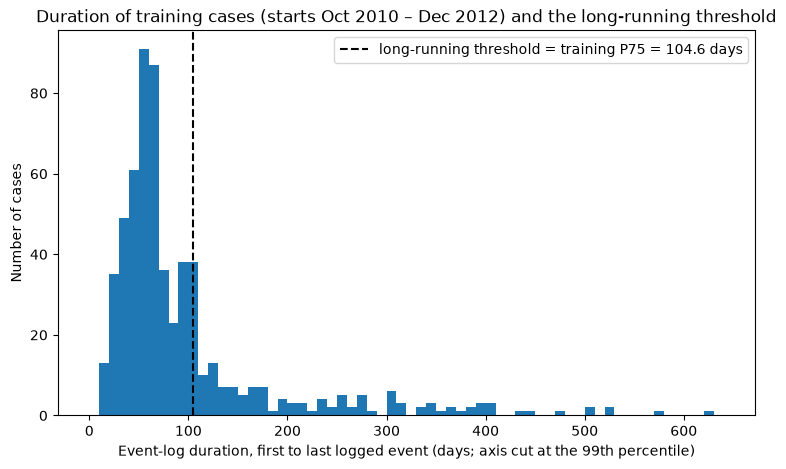

In [4]:
plt.figure(figsize=(9, 5))
train_durations = table.loc[split == M.TRAIN, "event_log_days"]
plt.hist(train_durations, bins=np.arange(0, train_durations.quantile(0.99) + 10, 10))
plt.axvline(locked["train_p75_days"], color="black", linestyle="--",
            label=f"long-running threshold = training P75 = {locked['train_p75_days']:.1f} days")
plt.title("Duration of training cases (starts Oct 2010 – Dec 2012) and the long-running threshold")
plt.xlabel("Event-log duration, first to last logged event (days; axis cut at the 99th percentile)")
plt.ylabel("Number of cases")
plt.legend()
plt.savefig(figures_dir / "final_duration_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. Final model results

In [5]:
result_table = pd.DataFrame(results).T[["prevalence", "precision", "recall", "f1", "roc_auc", "pr_auc"]].astype(float)
result_table.index.names = ["model", "split"]
print(f"All threshold-based metrics at the frozen probability threshold {THRESHOLD:.2f}. "
      "Prevalence = share of long-running cases = PR-AUC of random guessing.")
display(result_table.round(3))

All threshold-based metrics at the frozen probability threshold 0.25. Prevalence = share of long-running cases = PR-AUC of random guessing.


prevalence  precision  recall     f1  roc_auc  pr_auc
model               split                                                            
logistic (balanced) validation       0.291      0.300   1.000  0.462    0.609   0.377
                    test             0.140      0.144   1.000  0.252    0.528   0.155
random forest       validation       0.291      0.300   0.941  0.455    0.572   0.439
                    test             0.140      0.150   0.950  0.259    0.492   0.142

**Headline (test period, final random forest): ROC-AUC 0.49, PR-AUC 0.14, prevalence 0.14.**

In plain language: **the model did not reliably rank long-running cases above ordinary cases in the later test period.**
A ROC-AUC of 0.5 is what a coin flip achieves, and a PR-AUC equal to the prevalence is what random guessing achieves. The logistic
regression (ROC-AUC 0.53, PR-AUC 0.16) is not meaningfully better. The final model's 95% bootstrap interval for ROC-AUC
(about 0.36–0.62, notebook 04) includes chance.

The **high recall (95%) at the chosen threshold is not evidence of success**: at that threshold nearly every case was flagged.

# 5. Why accuracy and recall can mislead

The test-period confusion matrix of the final model:

| | predicted **not** long-running | predicted long-running |
|---|---|---|
| **actually not long-running** | TN = 15 | FP = 108 |
| **actually long-running** | FN = 1 | TP = 19 |

- **Recall = 19 / 20 = 95%.** It sounds excellent: almost every long-running case was caught.
- But the model raised **127 flags for 143 cases (89%)**. Only **19 of the 127 flags (15%)** were right; the other **108 flags were ordinary cases**.
- In an office, that means checking almost every file to find 19 problem cases, which is no better than checking files at random.

The table compares three simple strategies on the same test cases:

In [6]:
y_test = labels[split == M.TEST].to_numpy()
strategies = {
    f"our model (threshold {THRESHOLD:.2f})": locked["probability"][(FINAL, M.TEST)],
    "flag every case": np.ones(len(y_test)),
    "flag no case": np.zeros(len(y_test)),
}
teaching = pd.DataFrame({
    name: {key: M.evaluate(y_test, scores, THRESHOLD)[key] for key in ["accuracy", "precision", "recall", "f1", "tp", "fp"]}
    for name, scores in strategies.items()
}).T
teaching["cases flagged"] = teaching["tp"] + teaching["fp"]
display(teaching[["cases flagged", "accuracy", "precision", "recall", "f1"]].astype(float).round(3))

,cases flagged,accuracy,precision,recall,f1
our model (threshold 0.25),127.0,0.238,0.15,0.95,0.259
flag every case,143.0,0.140,0.14,1.00,0.245
flag no case,0.0,0.860,0.00,0.00,0.000


- **"Flag every case"** gets 100% recall and almost the same F1 as the model, so the model's F1 adds nothing.
- **"Flag no case"** gets the **highest accuracy (86%)** while catching nothing at all. Accuracy rewards ignoring the minority class.
- What matters operationally is **precision at a workable number of flags** and threshold-free ranking quality (**PR-AUC, ROC-AUC**).
  On those, the model shows no advantage on the test period.

The F1-based threshold rule chose this near "flag-everyone" setting on validation (see 04, Section 13.1). It was a pre-set rule and
was kept. A future design should fix a **top-k** or **minimum-precision** alert policy in advance.

# 6. Validation (2013) vs test (2014)

The 2013 validation period showed a **weak** signal (ROC-AUC 0.57–0.61; PR-AUC 0.38–0.44 against a prevalence of 0.29).
The 2014 test period showed **none**. A descriptive comparison of the periods (no model choices are made here):

In [7]:
follow_up = M.follow_up_flag(table["case_start"], df[F.TIMESTAMP].max(), 365)
period = pd.DataFrame({
    "cases": split.value_counts(),
    "long-running %": labels.groupby(split).mean().mul(100).round(1),
    "median duration (days)": table["event_log_days"].groupby(split).median().round(1),
    "≥ 365 d follow-up %": follow_up.groupby(split).mean().mul(100).round(1),
    "mean events by day 14": table["event_count_14d"].groupby(split).mean().round(1),
    "mean days since last event at day 14": table["days_since_last_event"].groupby(split).mean().round(1),
}).reindex([M.TRAIN, M.VALIDATION, M.TEST])
display(period)

,cases,long-running %,median duration (days),≥ 365 d follow-up %,mean events by day 14,mean days since last event at day 14
split,,,,,,
train,599,25.0,64.0,100.0,10.8,7.3
validation,175,29.1,73.0,100.0,12.9,9.1
test,143,14.0,60.5,65.0,15.4,9.3


**Possible reasons, none of which can be confirmed from this data:**

- **Process drift.** Working practices, rules or case mix may have changed between 2010–2012 (training) and 2014 (test), so the patterns learned no longer apply. The table shows one visible shift: the mean number of events logged by day 14 rises from about 11 (train) to 13 (validation) and 15 (test), so the same feature values mean something different over time.
- **Different positive prevalence.** Long-running cases fall from about 25–29% to 14% of the cohort. With only **20** long-running test cases, every metric is very uncertain.
- **Censoring / incomplete observation.** A third of the test cases had less than a year of follow-up. Long 2014 cases that were still open are missing, so the test positives are a selected subset (long, but closed before mid-2015).
- **Day-14 features may simply be insufficient.** The first two weeks mostly contain standard intake steps that almost every case goes through.
- **Cases may diverge later rather than early.** What makes a case long (objections, extra information, advice rounds) may happen after day 14.

The experiment is **not** changed in response to these observations; they are recorded as hypotheses for future work.

# 7. What the negative result means

> The experiment does **not** show that administrative case duration is unpredictable.
>
> It shows that **the information selected at Day 14 in this BPI dataset was not sufficient to build a model that reliably
> generalises to a later period.**

There is a real difference between:

- **"no evidence of a reliable signal here"**: what this experiment found, with this data, snapshot, features and test period; and
- **"proof that no signal exists"**: which this experiment cannot show. Richer data, a later snapshot or a larger test period could give a different answer.

A negative result from a careful, leakage-safe, time-aware evaluation is informative. It prevents a misleading early-warning tool
from being built on validation-only evidence.

# 8. Process-mining observations (descriptive only)

These observations come from earlier notebooks and are summarised here **to show why process data is complex**. They are
associations across all 917 eligible cases (using the locked training threshold for grouping). They are **not causal** and **not validated predictors**.

In [8]:
group = np.where(labels == 1, "long-running", "not long-running")
english = df.groupby(F.ACTIVITY)["activityNameEN"].agg(lambda s: s.value_counts().index[0])
observations = pd.DataFrame({
    "mean events by day 14": table["event_count_14d"].groupby(group).mean(),
    "mean gap between early events (days)": table["mean_inter_event_days"].groupby(group).mean(),
    f"reached '{english['01_HOOFD_101']}' by day 14 (%)": table["has_act_01_HOOFD_101"].groupby(group).mean() * 100,
    f"reached '{english['01_HOOFD_061']}' by day 14 (%)": table["has_act_01_HOOFD_061"].groupby(group).mean() * 100,
}).T.round(2)
display(observations)

variants = df.groupby(F.CASE, sort=False)[F.ACTIVITY].agg(tuple).value_counts()
print(f"Full process variants: {len(variants):,} distinct sequences among {df[F.CASE].nunique():,} cases; "
      f"{(variants == 1).sum():,} occur only once.")

,long-running,not long-running
mean events by day 14,9.81,12.59
mean gap between early events (days),1.23,0.82
reached 'registration date publication' by day 14 (%),47.06,64.51
reached 'start WABOprocedure' by day 14 (%),36.20,48.99


Full process variants: 1,170 distinct sequences among 1,199 cases; 1,155 occur only once.


- Longer-running cases had **fewer early events** on average and reached some **standard early steps less often** by day 14.
- Their **mean waiting gap** between early events was somewhat larger.
- Yet these group differences did not translate into a model that works on the later period: the groups **overlap heavily**.
- Full process paths are **extremely heterogeneous**: almost every case follows its own sequence. Simple path-based rules are unlikely to work, and process data needs careful abstraction.

# 9. What the proof of concept successfully demonstrated

**The ML result is negative, but the data-science pipeline is successful.** Each capability below was built, used and checked:

| Capability | Where |
|---|---|
| XES event-log ingestion, with checksum-verified read-only raw data | `01_data_loading`, all notebooks |
| Case reconstruction and data-quality audit (durations, completion fields, anomalies) | `02_eda`, `02b_target_definition` |
| Point-in-time snapshots (only events ≤ day 14) | `src/features.py`, `03_feature_engineering` |
| Leakage-safe feature engineering, with an automated future-perturbation test | `03`, `tests/test_features.py` |
| Train-only target threshold (104.56 days) | `src/models.py`, `04_modeling` |
| Train-only activity vocabulary and preprocessing | `src/features.py`, `src/models.py` |
| Chronological validation, with choices frozen before the test | `04_modeling` |
| Reproducible scikit-learn pipelines, re-run and matched here | `src/models.py`, this notebook |
| Evaluation beyond accuracy (PR-AUC, ROC-AUC, bootstrap intervals, robustness checks) | `04_modeling`, this notebook |
| Tests and reproducibility (13 unit tests, top-to-bottom notebook runs) | `tests/` |

# 10. Implications for SPAR

The BPI experiment suggests that **an operational system intended to support predictive analytics later should capture richer,
structured context from the beginning**. In BPI 2015, most early information is a stream of activity codes with date-level
timestamps and fields of unclear meaning. Many potentially relevant facts are simply not recorded in a usable, point-in-time form.

Candidate information a future SPAR system could record (each one a **candidate signal to be tested later**, not a guaranteed improvement):

| Information | Why it could matter |
|---|---|
| Activity / event history with exact timestamps | the basis for any point-in-time feature |
| Formal workflow state and a timestamp for **each state transition** | where the case is, and for how long |
| Process type and task / request type | different kinds of cases have different "normal" durations |
| Responsible unit | routing and hand-over structure (not individual performance) |
| Routing and request dependencies | waiting on another unit, another case or an external party |
| Waiting on another unit / user | explicit waiting time instead of inferred gaps |
| Due-date changes (with history) | extensions as events, not overwritten values |
| Structured reason for hold / delay | e.g. "missing documents", "external advice" |
| Workload / context at prediction time | queue size of the unit when the case arrives |

Whether any of these improves prediction must be **tested the same way**: point-in-time, train-only, chronologically evaluated.

> **No employee ranking or automated personnel evaluation is intended.** Resource and unit information describes process
> structure. Any risk score would support human attention and prioritisation, never automatic decisions about cases or people.

# 11. Why SPAR data could be better suited later

BPI 2015 is an **external, historical** event log, extracted for a research challenge. Its fields were not designed for prediction:
their meaning is partly undocumented, many timestamps are dates only, and some attributes hold values written later than the
event they belong to (notebook 03).

A future SPAR dataset could be **designed** for this purpose, with:

- **explicit semantics**: documented meaning for every field and code;
- **consistent timestamps**: full date-time for every event;
- **known point-in-time availability**: a record of *when* each value became known (no silent overwrites);
- **typed events**: clear event categories instead of hundreds of free codes;
- **workflow relationships**: links between cases, sub-cases and requests;
- **structured reasons**: coded reasons for holds, returns and extensions;
- **dependency information**: what or whom a case is waiting for.

This would make future predictive experiments **more interpretable and auditable**. It does not guarantee better predictive
performance; that can only be established by testing on SPAR data.

# 12. Limitations

- **One municipality** (BPI 2015, Municipality 1), about 900 eligible cases.
- **Historical data (2010–2015)**; processes and rules may have changed since.
- **Date-level timestamps**: same-day event order follows the source file.
- **Ambiguous field semantics**: e.g. `requestComplete`, `caseStatus`, `planned`, `dueDate` are undocumented.
- **Incomplete later cohorts**: recent cases had less time to finish (right-censoring).
- **Only closed cases have a known final duration**; open cases are outside the labelled cohort.
- **The 14-day snapshot is one design choice**; other prediction points were not tested.
- **No legal-deadline target**: "long-running" is relative to this municipality's own durations.
- **External data, not Montenegro / SPAR data**: no conclusion transfers without local data.
- **Small test period**: 20 long-running test cases make every test metric uncertain.

# 13. Future work (not done here — the primary result stays locked)

- **Later prediction snapshots** (e.g. day 30), designed and evaluated as a new pre-registered experiment.
- **Richer domain attributes** whose point-in-time availability is confirmed (e.g. `case:parts`).
- **Multiple BPI 2015 municipalities** for more cases and a cross-municipality test.
- **A SPAR-native dataset** with the properties in Section 11.
- **Rolling temporal validation** (several train/test windows) for more stable estimates.
- **Top-k operational alert policies** (e.g. "flag the 10% highest-risk cases") fixed before testing.

# 14. Presentation takeaways

1. **Problem:** Long-running administrative cases are hard to spot early; we tested whether information from a case's first 14 days can flag them.
2. **Method:** We built a leakage-safe, point-in-time pipeline with a training-only target and strictly chronological evaluation.
3. **Result:** On the later 2014 test period, the models were no better than chance (ROC-AUC 0.49, PR-AUC 0.14 at 14% prevalence).
4. **Lesson:** 95% recall looked good but meant flagging almost every case; honest, time-aware evaluation prevented an over-optimistic conclusion.
5. **SPAR:** Useful predictive analytics will depend on capturing rich, well-defined, time-stamped process data from the start, and on testing it just as carefully.

# 15. Recommended final figures

| # | Figure | File (in `outputs/figures/`) | Notebook | Message |
|---|---|---|---|---|
| 1 | Duration distribution and the long-running threshold | `final_duration_threshold.png` | 05 | What "long-running" means (training P75 = 104.6 days) |
| 2 | Cases started / closed per year | `cases_by_year.png` | 02 | Data coverage, partial years, censoring, and the time-based split |
| 3 | Early activity by day 14, shorter vs longer cases | `feature_early_activity_share.png` | 03 | What day-14 features look like, and how much the groups overlap |
| 4 | Precision–recall curve, test period | `model_pr_curve_test.png` | 04 | The core result: both models sit on the no-skill line |
| 5 | Confusion matrix, test period | `model_confusion_matrix_test.png` | 04 | Why 95% recall is not success (108 false alarms) |
| 6 | Top activities (process complexity) | `top_activities.png` | 02 | What the process consists of; with "1,170 variants for 1,199 cases" as a caption |

*Backup:* `model_top_features.png` (associations learned by the logistic model; only with the caveat that the model shows no test signal).
Figure 3 uses the exploratory, non-final grouping from notebook 03; its caption should say so.

# 16. Capstone abstract

**Early Prediction of Long-Running Administrative Cases: A Proof of Concept for SPAR**

Administrative cases that take much longer than usual are costly, and an early warning could help staff decide where to look first.
This capstone tests whether information available 14 days after a case starts can predict whether it will become long-running,
defined as exceeding the 75th percentile of training-period durations (104.6 days). Using the public BPI Challenge 2015 event log
of one Dutch municipality (1,199 permit cases, 52,217 events), we reconstructed cases, built leakage-safe point-in-time features
from the first 14 days, and trained a logistic-regression baseline and a random forest. Evaluation was strictly chronological:
the threshold, activity vocabulary and preprocessing were learned on 2010–2012 cases, model choices were made on 2013, and 2014
was scored once. A weak signal appeared in 2013, but on the 2014 test period neither model ranked cases better than chance (random
forest ROC-AUC 0.49; PR-AUC 0.14 at a prevalence of 0.14). The pipeline worked; the early information did not generalise.
For SPAR, the lesson is that predictive analytics depends on capturing rich, well-defined, time-stamped process context from
the start, and on evaluating it honestly before relying on any risk score.

# 17. Spoken conclusion (about 55–60 seconds)

> We asked a simple question: can the first two weeks of a permit case tell us whether it will turn into a long-running case?
>
> To answer it honestly, we built the whole pipeline: from a raw event log to day-14 features that use no future information, a
> target learned only from the past, and an evaluation that respects time.
>
> On 2013 data, the models showed a faint signal. But on 2014, our real "future" test, they did no better than chance. And a
> 95 percent recall sounds great, until you see that we flagged almost every case.
>
> That is not a failure of the method. It is exactly what an honest evaluation is for. It tells us that these early records, in
> this dataset, are not enough.
>
> For SPAR, the message is clear: if we want useful predictions later, we need to record richer, well-defined process data from
> day one, and test it just as carefully. Thank you.

# 18. Final statement

- **Locked primary result:** Day-14 random forest, test ROC-AUC 0.49, PR-AUC 0.14 (prevalence 0.14). Reproduced above.
- **No test-driven tuning:** nothing in this notebook changes the features, snapshot, target, model or threshold.
- **Associations are not causes;** no employee-performance interpretation is made.